In [1]:
import yfinance as yf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import datetime as dt
import warnings
warnings.filterwarnings('ignore')

YF.download() has changed argument auto_adjust default to True


[*********************100%***********************]  7 of 7 completed


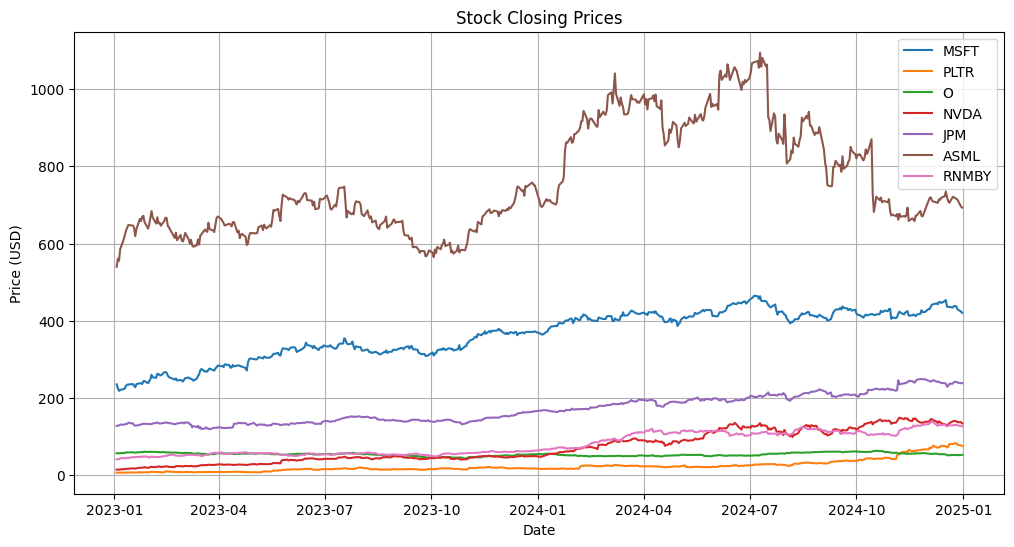

In [2]:
# List of stock tickers
stocks = [ 'MSFT','PLTR', 'O', 'NVDA', 'JPM', 'ASML', 'RNMBY']

# Download data
data = yf.download(stocks, start='2023-01-01', end='2025-01-01')

# Plot the closing prices
plt.figure(figsize=(12, 6))
for stock in stocks:
    plt.plot(data['Close'][stock], label=stock)

plt.title('Stock Closing Prices')
plt.xlabel('Date')
plt.ylabel('Price (USD)')
plt.legend()
plt.grid()
plt.show()


In [3]:
df = data.drop(columns=["High","Low","Open","Volume"])

In [4]:
df.head()

Price            Close                                                      \
Ticker            ASML         JPM        MSFT       NVDA          O  PLTR   
Date                                                                         
2023-01-03  539.838318  127.490334  235.240021  14.303280  56.660343  6.39   
2023-01-04  560.721863  128.679184  224.949860  14.736925  57.379696  6.58   
2023-01-05  555.309387  128.650650  218.282883  14.253322  56.296223  6.32   
2023-01-06  585.298767  131.112442  220.855408  14.846834  56.909008  6.40   
2023-01-09  610.327576  130.570679  223.005753  15.615205  57.459621  6.50   

Price                  
Ticker          RNMBY  
Date                   
2023-01-03  41.113846  
2023-01-04  40.948376  
2023-01-05  41.542114  
2023-01-06  43.430389  
2023-01-09  44.481598

In [5]:
daily_returns = df.pct_change()
daily_returns = daily_returns.dropna()
daily_returns

Price          Close                                                    \
Ticker          ASML       JPM      MSFT      NVDA         O      PLTR   
Date                                                                     
2023-01-04  0.038685  0.009325 -0.043743  0.030318  0.012696  0.029734   
2023-01-05 -0.009653 -0.000222 -0.029638 -0.032816 -0.018883 -0.039514   
2023-01-06  0.054005  0.019135  0.011785  0.041640  0.010885  0.012658   
2023-01-09  0.042762 -0.004132  0.009736  0.051753  0.009675  0.015625   
2023-01-10  0.019410  0.008954  0.007617  0.017981 -0.008655  0.030769   
...              ...       ...       ...       ...       ...       ...   
2024-12-24 -0.001844  0.016444  0.009374  0.003938  0.004528  0.020944   
2024-12-26 -0.005349  0.003425 -0.002777 -0.002068 -0.003193 -0.002913   
2024-12-27 -0.003171 -0.008102 -0.017302 -0.020868 -0.007726 -0.037253   
2024-12-30 -0.024440 -0.007671 -0.013240  0.003503  0.001329 -0.024026   
2024-12-31 -0.004410  0.001630 -0.007838 -0.023274  0.012896 -0.020083   

Price                 
Ticker         RNMBY  
Date                  
2023-01-04 -0.004025  
2023-01-05  0.014500  
2023-01-06  0.045454  
2023-01-09  0.024204  
2023-01-10 -0.004595  
...              ...  
2024-12-24  0.002026  
2024-12-26  0.006776  
2024-12-27 -0.014564  
2024-12-30 -0.007545  
2024-12-31 -0.008151  

[501 rows x 7 columns]

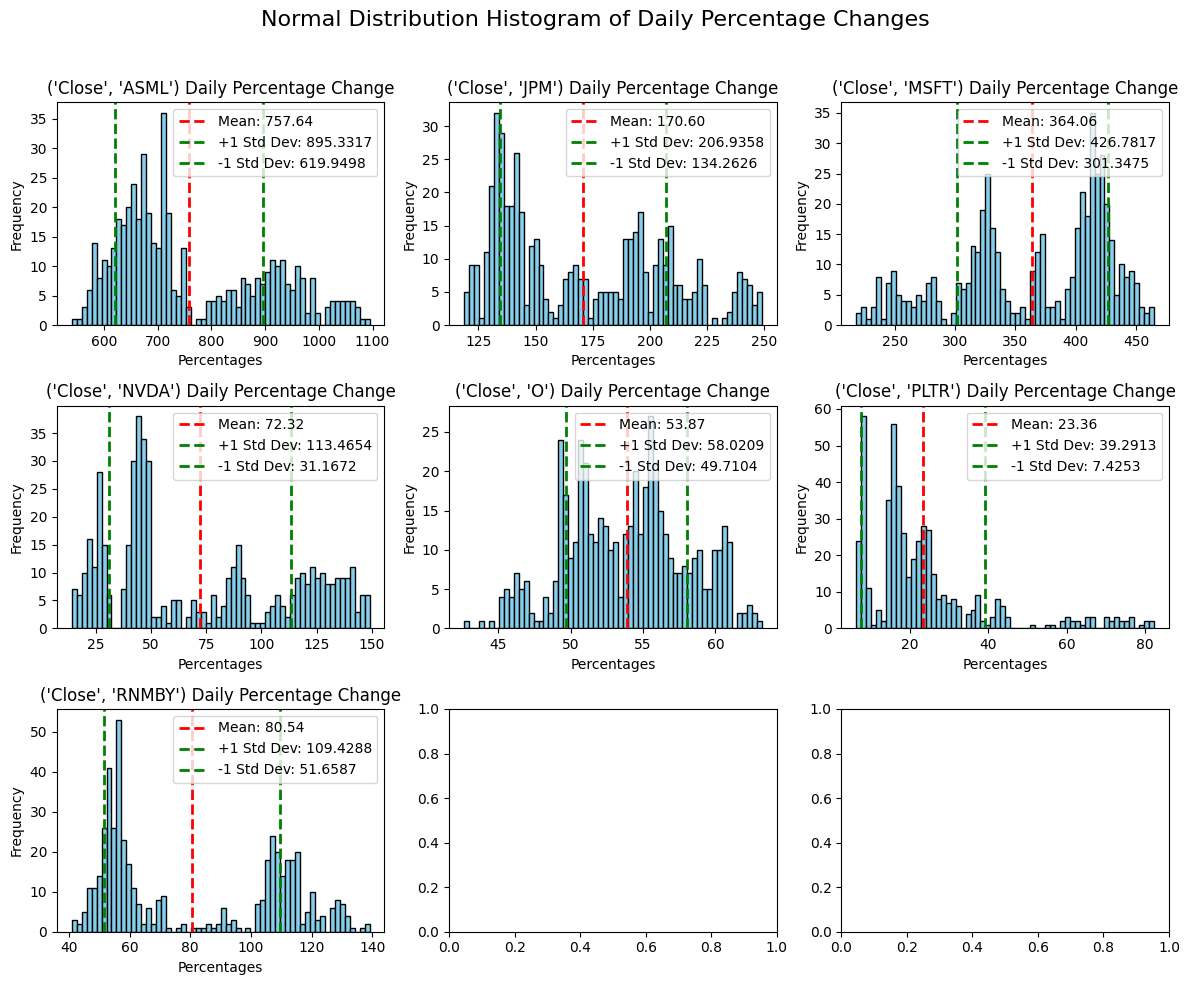

In [10]:
# Plot histograms for each stock's normalized percentage changes
fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(12, 10))
fig.suptitle("Normal Distribution Histogram of Daily Percentage Changes", fontsize=16)

# Flatten the axes array for easy iteration
axes = axes.flatten()

# Plot each column's histogram and add lines for mean and standard deviations
for i, column in enumerate(df.columns):
    # Plot the histogram
    axes[i].hist(df[column], bins=60, color='skyblue', edgecolor='black')
    
    # Calculate mean and standard deviation
    mean = df[column].mean()
    std_dev = df[column].std()
    
    # Plot the mean line
    axes[i].axvline(mean, color='red', linestyle='dashed', linewidth=2, label=f"Mean: {mean:.2f}")
    
    # Plot the standard deviation lines
    axes[i].axvline(mean + std_dev, color='green', linestyle='dashed', linewidth=2, label=f"+1 Std Dev: {(mean + std_dev):.4f}")
    axes[i].axvline(mean - std_dev, color='green', linestyle='dashed', linewidth=2, label=f"-1 Std Dev: {(mean - std_dev):.4f}")
    
    # Set titles and labels
    axes[i].set_title(f"{column} Daily Percentage Change")
    axes[i].set_xlabel("Percentages")
    axes[i].set_ylabel("Frequency")
    axes[i].legend(loc="upper right")

plt.tight_layout(rect=[0, 0, 1, 0.96])  # Adjust layout to fit title
plt.show()

<Axes: xlabel='Date'>

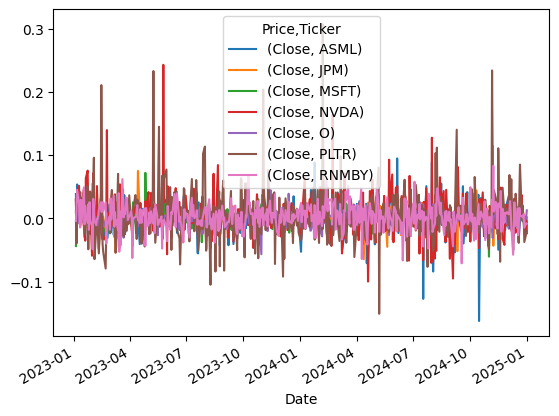

In [11]:
daily_returns.plot()

<Axes: xlabel='Date'>

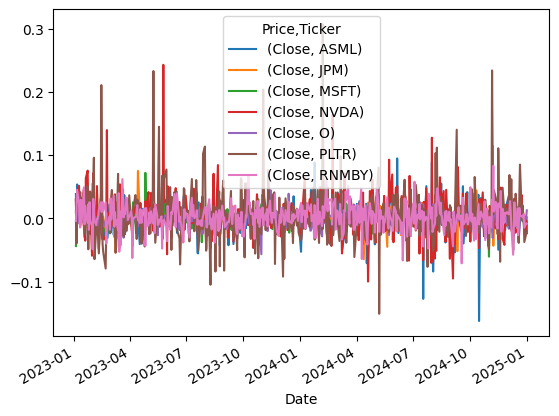

In [12]:
daily_returns.plot()

In [13]:
mean = daily_returns.mean()
mean

Price  Ticker
Close  ASML      0.000799
       JPM       0.001347
       MSFT      0.001263
       NVDA      0.004971
       O        -0.000079
       PLTR      0.005785
       RNMBY     0.002446
dtype: float64

In [14]:
std_dev = daily_returns.std()
std_dev

Price  Ticker
Close  ASML      0.024355
       JPM       0.013963
       MSFT      0.014286
       NVDA      0.031804
       O         0.011667
       PLTR      0.042078
       RNMBY     0.019973
dtype: float64

In [15]:
variance = daily_returns.var()
variance

Price  Ticker
Close  ASML      0.000593
       JPM       0.000195
       MSFT      0.000204
       NVDA      0.001012
       O         0.000136
       PLTR      0.001771
       RNMBY     0.000399
dtype: float64

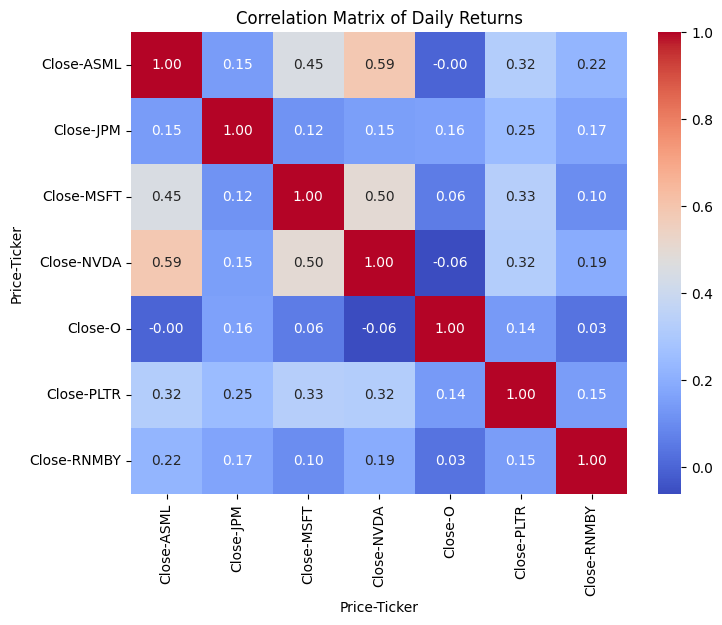

In [16]:
# Calculate the correlation matrix
correlation_matrix = daily_returns.corr()
covariance_matrix = daily_returns.cov()

# Plot the correlation matrix as a heatmap
plt.figure(figsize=(8, 6))
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title('Correlation Matrix of Daily Returns')
plt.show()


<Axes: xlabel='Price-Ticker', ylabel='Price-Ticker'>

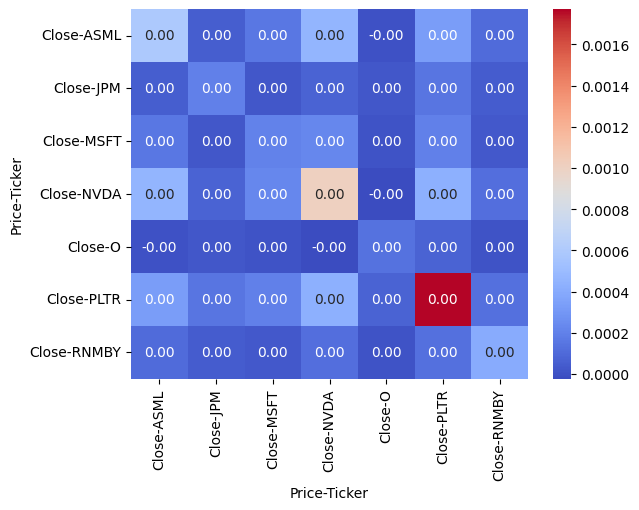

In [17]:
sns.heatmap(covariance_matrix, annot=True, cmap='coolwarm', fmt=".2f")

In [18]:
def generate_weights(x):
  """Generates a list of weights that sum up to 1 (at most) with 3 decimal places.

  Args:
    x: The number of weights to generate.

  Returns:
    A list of weights.
  """
  weights = np.around(np.random.dirichlet(np.ones(x), size=1)[0], 3)
  return weights
print(generate_weights(3))

[0.504 0.139 0.357]


In [19]:
def portfolio_return(weights, mean_returns):
  """Calculates the portfolio return.

  Args:
    weights: A list of weights for each asset in the portfolio.
    mean_returns: A list of mean returns for each asset in the portfolio.

  Returns:
    The portfolio return.
  """
  return np.dot(weights, mean_returns)


In [20]:
def portfolio_risk(weights, cov_matrix):
  """Calculates the portfolio risk (standard deviation).

  Args:
    weights: A list of weights for each asset in the portfolio.
    cov_matrix: The covariance matrix of asset returns.

  Returns:
    The portfolio risk (standard deviation).
  """
  portfolio_variance = np.dot(weights.T, np.dot(cov_matrix, weights))
  portfolio_risk = np.sqrt(portfolio_variance)
  return portfolio_risk



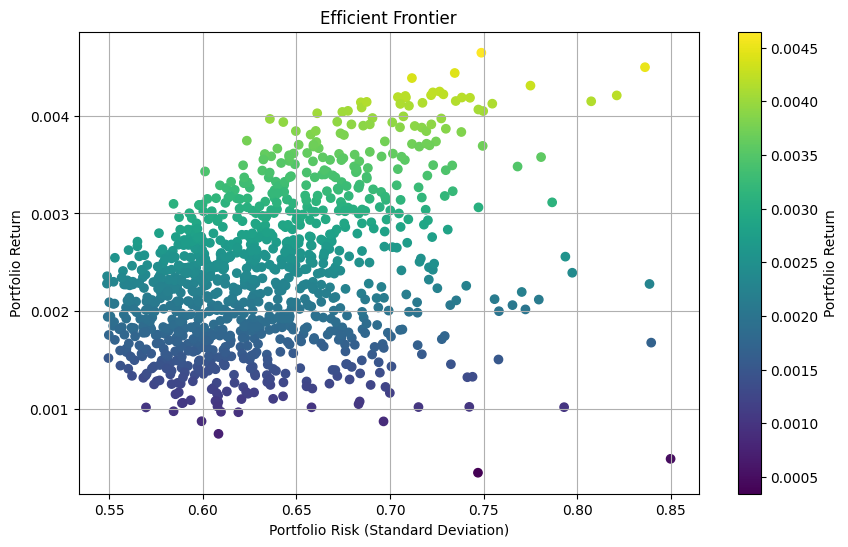

In [21]:
portfolio_returns = []
portfolio_risks = []

for _ in range(1000):
  weights = generate_weights(len(stocks))
  portfolio_returns.append(portfolio_return(weights, mean))
  portfolio_risks.append(portfolio_risk(weights, correlation_matrix))

# Create a scatter plot of portfolio returns vs. portfolio risks
plt.figure(figsize=(10, 6))
plt.scatter(portfolio_risks, portfolio_returns, c=portfolio_returns, marker='o')
plt.xlabel('Portfolio Risk (Standard Deviation)')
plt.ylabel('Portfolio Return')
plt.title('Efficient Frontier')
plt.colorbar(label='Portfolio Return')
plt.grid(True)
plt.show()



🔴 Best Portfolio (Max Sharpe Ratio):
Apples: 23.60%
Bananas: 17.32%
Oranges: 21.71%
Grapes: 19.86%
Pineapples: 17.50%

🔵 Best Portfolio (Min Volatility):
Apples: 20.63%
Bananas: 17.55%
Oranges: 21.63%
Grapes: 19.12%
Pineapples: 21.07%

🟠 Highest Risk, Lowest Return Portfolio:
Apples: 8.06%
Bananas: 18.36%
Oranges: 0.62%
Grapes: 16.53%
Pineapples: 56.44%

🟢 Highest Risk, Highest Return Portfolio:
Apples: 6.46%
Bananas: 2.07%
Oranges: 8.15%
Grapes: 76.46%
Pineapples: 6.86%

🟣 Highest Return Portfolio:
Apples: 61.11%
Bananas: 0.01%
Oranges: 23.26%
Grapes: 11.72%
Pineapples: 3.91%

🟤 Lowest Return Portfolio:
Apples: 8.06%
Bananas: 18.36%
Oranges: 0.62%
Grapes: 16.53%
Pineapples: 56.44%


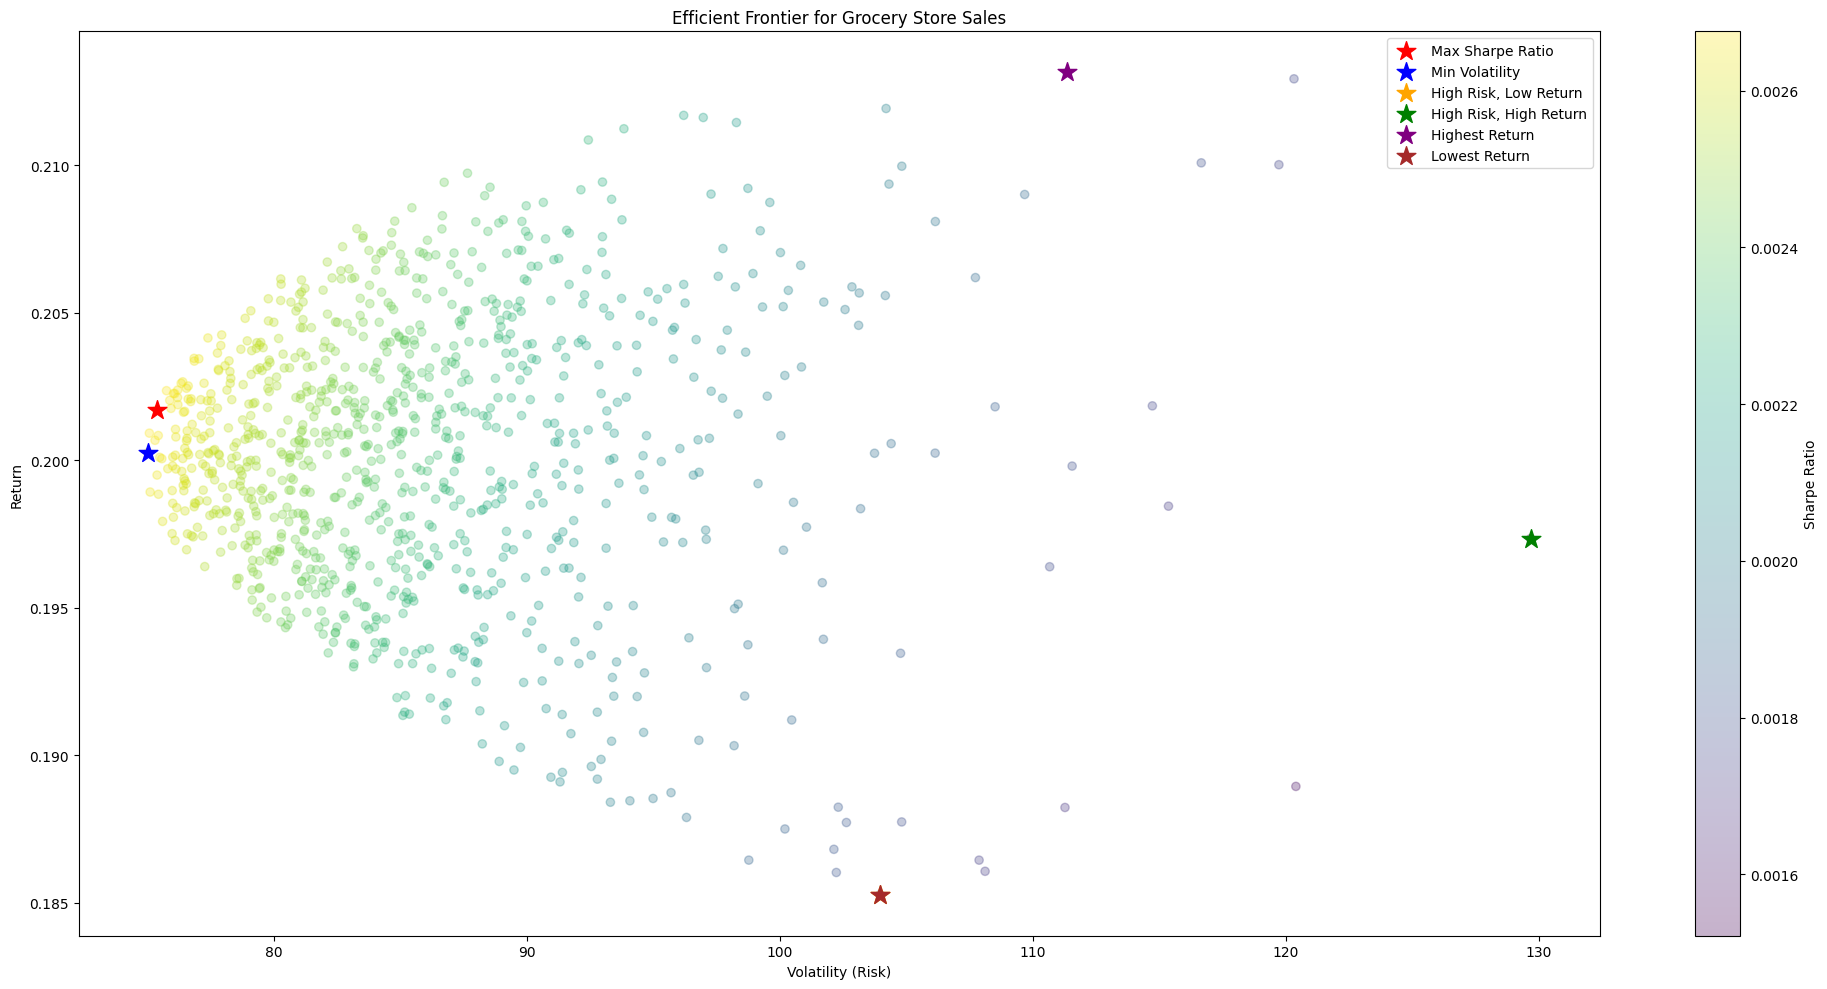

In [22]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

def plot_efficient_frontier(sales_data):
    df = pd.DataFrame(sales_data, columns=['Item', 'Quantity_Sold', 'Price_per_Qty'])
    df['Total_Sales'] = df['Quantity_Sold'] * df['Price_per_Qty']

    returns = df['Total_Sales'] / df['Total_Sales'].sum()
    cov_matrix = np.cov(df['Total_Sales'], rowvar=False)

    num_assets = len(returns)
    num_portfolios = 1000
    results = np.zeros((3, num_portfolios))
    all_weights = []

    for i in range(num_portfolios):
        weights = np.random.random(num_assets)
        weights /= np.sum(weights)

        portfolio_return = np.sum(weights * returns)
        portfolio_stddev = np.sqrt(np.dot(weights.T, np.dot(cov_matrix, weights)))

        results[0, i] = portfolio_return
        results[1, i] = portfolio_stddev
        results[2, i] = portfolio_return / portfolio_stddev

        all_weights.append(weights)

    # Find best portfolios
    max_sharpe_idx = np.argmax(results[2])
    min_vol_idx = np.argmin(results[1])
    
    # Highest risk, lowest return: highest volatility with lowest return
    high_risk_low_return_idx = np.argmax(results[1]) if results[0, np.argmax(results[1])] < 0 else np.argmin(results[0])
    
    # Highest risk, highest return: highest volatility with highest return
    high_risk_high_return_idx = np.argmax(results[1]) if results[0, np.argmax(results[1])] > 0 else np.argmax(results[0])

    # Highest return portfolio: portfolio with the highest return
    highest_return_idx = np.argmax(results[0])

    # Lowest return portfolio: portfolio with the lowest return
    lowest_return_idx = np.argmin(results[0])

    best_sharpe_weights = all_weights[max_sharpe_idx]
    min_vol_weights = all_weights[min_vol_idx]

    # Print optimal weights
    print("\n🔴 Best Portfolio (Max Sharpe Ratio):")
    for i, weight in enumerate(best_sharpe_weights):
        print(f"{df['Item'][i]}: {weight:.2%}")

    print("\n🔵 Best Portfolio (Min Volatility):")
    for i, weight in enumerate(min_vol_weights):
        print(f"{df['Item'][i]}: {weight:.2%}")

    print("\n🟠 Highest Risk, Lowest Return Portfolio:")
    for i, weight in enumerate(all_weights[high_risk_low_return_idx]):
        print(f"{df['Item'][i]}: {weight:.2%}")

    print("\n🟢 Highest Risk, Highest Return Portfolio:")
    for i, weight in enumerate(all_weights[high_risk_high_return_idx]):
        print(f"{df['Item'][i]}: {weight:.2%}")

    print("\n🟣 Highest Return Portfolio:")
    for i, weight in enumerate(all_weights[highest_return_idx]):
        print(f"{df['Item'][i]}: {weight:.2%}")

    print("\n🟤 Lowest Return Portfolio:")
    for i, weight in enumerate(all_weights[lowest_return_idx]):
        print(f"{df['Item'][i]}: {weight:.2%}")

    # Plot the efficient frontier
    plt.figure(figsize=(20, 10))
    plt.scatter(results[1, :], results[0, :], c=results[2, :], cmap='viridis', marker='o', alpha=0.3)
    plt.colorbar(label='Sharpe Ratio')
    plt.scatter(results[1, max_sharpe_idx], results[0, max_sharpe_idx], c='red', marker='*', s=200, label='Max Sharpe Ratio')
    plt.scatter(results[1, min_vol_idx], results[0, min_vol_idx], c='blue', marker='*', s=200, label='Min Volatility')
    plt.scatter(results[1, high_risk_low_return_idx], results[0, high_risk_low_return_idx], c='orange', marker='*', s=200, label='High Risk, Low Return')
    plt.scatter(results[1, high_risk_high_return_idx], results[0, high_risk_high_return_idx], c='green', marker='*', s=200, label='High Risk, High Return')
    plt.scatter(results[1, highest_return_idx], results[0, highest_return_idx], c='purple', marker='*', s=200, label='Highest Return')
    plt.scatter(results[1, lowest_return_idx], results[0, lowest_return_idx], c='brown', marker='*', s=200, label='Lowest Return')
    plt.title('Efficient Frontier for Grocery Store Sales')
    plt.xlabel('Volatility (Risk)')
    plt.ylabel('Return')
    plt.tight_layout()
    plt.legend()
    plt.show()

# Example sales data
sales_data = [
    ['Apples', 1000, 2.0],
    ['Bananas', 1200, 1.5],
    ['Oranges', 800, 2.5],
    ['Grapes', 600, 3.0],
    ['Pineapples', 400, 4.0]
]

plot_efficient_frontier(sales_data)
